# BI10 Round 02 · Challenge 1 — Final Scoring Calibration & Approval Alignment
**Scope:** repair masked validation · select defensible scoring parameters · rescore 1M customers · evaluate score stability/cap · test **Approval Rate** as *contemporaneous business association only* · export final segments.

**Inputs (read-only):** `C1_STEP3_OUTPUT/run_*/tables/03_customer_feature_mart.csv`, `clean_data/CONTRACT_clean.csv` (and, if present, V2 config/CSV for comparison). **Outputs:** NEW `C1_FINAL_VALIDATION_OUTPUT/run_*/`.

**Guardrails:** Unconfirmed income period → ODSR is a proxy; DUE and WO lack event timestamps → no PD / forecasting claim; `AMT_CREDIT` is **not** outstanding balance. `APPROVAL_ALIGNMENT` is descriptive (score constructed with post-decision information). The 0–100 score is *not* a probability.

## 01 · Cấu hình & thư mục — không ghi đè đầu ra cũ

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.special import betaln, gammaln
from IPython.display import display

MART_OVERRIDE = None              # Exact path if auto discovery fails
CONTRACT_OVERRIDE = None          # Exact path if auto discovery fails
PROJECT_OVERRIDE = None           # Folder containing clean_data and C1_STEP3_OUTPUT
CONFIG = {
    'version': 'BI10_FHS_V2.1_CALIBRATED', 'seed': 20261018,
    'capacity_weights': [.40,.50,.60], 'a1_weights': [.70,.80,.90],
    'policy_capacity_weight': .50, 'policy_a1_weight': .80,
    'odsr_good': .10, 'odsr_stress': .50, 'a2_quantiles':[.10,.90],
    'prior_k_reference':5., 'prior_k_bounds':[2.,10.], 'wo_cap':50.,
    'reference_group_min':200, 'holdout_fraction':.20,
    'imputation_min_mae_advantage':.10,
    'diag_bands':[0,20,40,60,80,100],
    'approval_chunk_rows':200000, 'minimum_approval_cases_per_band':100,
}
ROOTS = list(dict.fromkeys([Path.cwd().resolve(), Path.cwd().resolve().parent,
                             Path.cwd().resolve().parent.parent]))
if PROJECT_OVERRIDE: ROOTS.insert(0,Path(PROJECT_OVERRIDE).expanduser().resolve())
print('Current folder:',Path.cwd().resolve())

Current folder: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET


## 02 · Xác định đúng Feature Mart, hợp đồng sạch và V2 baseline

In [2]:
def find_latest(globs,override=None,required=True):
    if override:
        p=Path(override).expanduser().resolve()
        if not p.is_file():raise FileNotFoundError(p)
        return p
    found=[]
    for root in ROOTS:
        for prefix in [root,root/'BI10_ROUND02_DATASET']:
            for pattern in globs:found.extend(prefix.glob(pattern))
    found=[p.resolve() for p in set(found) if p.is_file()]
    if not found:
        if required:raise FileNotFoundError('Không tìm được nguồn trong: '+str(globs)+'; dùng biến OVERRIDE.')
        return None
    return max(found,key=lambda p:p.stat().st_mtime)

MART=find_latest(['C1_STEP3_OUTPUT/run_*/tables/03_customer_feature_mart.csv'],MART_OVERRIDE)
CONTRACT=find_latest(['clean_data/CONTRACT_clean.csv'],CONTRACT_OVERRIDE,required=False)
PREVIOUS=find_latest(['C1_STEP4_V2_OUTPUT/run_*/tables/02_customer_fhs_v2.csv'],required=False)
BASE=Path(PROJECT_OVERRIDE).expanduser().resolve() if PROJECT_OVERRIDE else MART.parents[3]
OUT=BASE/'C1_FINAL_VALIDATION_OUTPUT'/('run_'+datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid4().hex[:6])
TABLES=OUT/'tables'; FIGS=OUT/'figures'
TABLES.mkdir(parents=True,exist_ok=False);FIGS.mkdir()
print('MART:',MART,'\nCONTRACT:',CONTRACT,'\nPREVIOUS:',PREVIOUS,'\nOUTPUT:',OUT)

MART: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\tables\03_customer_feature_mart.csv 
CONTRACT: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\clean_data\CONTRACT_clean.csv 
PREVIOUS: C:\Users\nguyen\Desktop\C1_STEP4_V2_OUTPUT\run_20261018_113802_840b33\tables\02_customer_fhs_v2.csv 
OUTPUT: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_FINAL_VALIDATION_OUTPUT\run_20261018_122943_11af97


## 03 · Nạp đúng các cột cần dùng — 1 dòng / khách hàng

In [3]:
NEEDED=['SKP_CLIENT','A1_ODSR_IF_INCOME_MONTHLY','A2_RESIDUAL_IF_INCOME_MONTHLY',
 'P1_DUE_RATE_RESOLVED_PROXY','P2_DUE_FLAG_BREADTH_AMONG_AFFECTED','P3_WRITTEN_OFF_HISTORY',
 'income_candidate','active_annuity_known','n_active_cases_with_annuity',
 'n_active_cases_missing_annuity','n_payment_observable_resolved_proxy','n_due_resolved_proxy',
 'n_written_off_cases','n_signed_cases','n_integrity_failed_cases','income_period_monthly_confirmed']
OPTIONAL=['income_source_product','income_source_application_time','income_spread_across_cases']
cols=pd.read_csv(MART,nrows=0).columns.tolist()
missing=set(NEEDED)-set(cols)
if missing:raise ValueError('Mart thiếu cột: '+str(sorted(missing)))
df=pd.read_csv(MART,usecols=NEEDED+[c for c in OPTIONAL if c in cols],dtype={'SKP_CLIENT':'string'},low_memory=False)
if df.SKP_CLIENT.isna().any() or df.SKP_CLIENT.duplicated().any():raise ValueError('Customer key NULL/trùng')
for c in NEEDED:
    if c not in ['SKP_CLIENT','income_period_monthly_confirmed']:
        df[c]=pd.to_numeric(df[c],errors='coerce')
df['PRODUCT_CONTEXT']=(df['income_source_product'].astype('string').str.upper().str.strip()
    if 'income_source_product' in df else pd.Series(pd.NA,index=df.index,dtype='string'))
dates=pd.to_datetime(df['income_source_application_time'],errors='coerce') if 'income_source_application_time' in df else pd.Series(pd.NaT,index=df.index)
df['COHORT_YEAR']=dates.dt.year.astype('Int64')
df['INCOME_MONTHLY_CONFIRMED']=df.income_period_monthly_confirmed.astype('string').str.lower().isin(['true','1','yes'])
print('CUSTOMERS:',len(df),'| DISTINCT:',df.SKP_CLIENT.nunique())

CUSTOMERS: 1000528 | DISTINCT: 1000528


## 04 · Eligibility V2 tương thích — kiểm toán riêng Capacity và Payment

In [4]:
n_ok=df.n_active_cases_with_annuity.fillna(0).to_numpy(float)
n_miss=df.n_active_cases_missing_annuity.fillna(0).to_numpy(float)
n_obs=df.n_payment_observable_resolved_proxy.fillna(0).to_numpy(float)
n_due=df.n_due_resolved_proxy.fillna(0).to_numpy(float)
n_wo=df.n_written_off_cases.fillna(0).to_numpy(float)
n_signed=df.n_signed_cases.fillna(0).to_numpy(float)
inc=df.income_candidate.to_numpy(float);ann=df.active_annuity_known.to_numpy(float)
r=df.A1_ODSR_IF_INCOME_MONTHLY.to_numpy(float);resid=df.A2_RESIDUAL_IF_INCOME_MONTHLY.to_numpy(float)
p1=df.P1_DUE_RATE_RESOLVED_PROXY.to_numpy(float)
no_active=(n_ok+n_miss==0)
active_known=(n_ok>0)&(n_miss==0)&(ann>0)
base_integrity=(df.n_integrity_failed_cases.fillna(0).to_numpy(float)==0)
capacity_counts=(n_ok>=0)&(n_miss>=0)
payment_counts=(n_obs>0)&(n_due>=0)&(n_due<=n_obs)&(n_signed>0)&(n_wo>=0)&(n_wo<=n_signed)
expected_ann=np.where(no_active,0,ann)
ci=base_integrity&capacity_counts&(inc>0)&np.isfinite(inc)&(no_active|active_known)&np.isfinite(r)&np.isfinite(resid)&(r>=0)
ci &= np.isclose(r,expected_ann/np.where(inc>0,inc,np.nan),rtol=1e-6,atol=1e-7)
ci &= np.isclose(resid,inc-expected_ann,rtol=1e-6,atol=.01)
wo_flag=df.P3_WRITTEN_OFF_HISTORY.to_numpy(float)
pi=base_integrity&payment_counts&np.isfinite(p1)&(p1>=0)&(p1<=1)&np.isin(wo_flag,[0,1])
pi &= np.isclose(p1,n_due/np.where(n_obs>0,n_obs,np.nan),rtol=1e-6,atol=1e-7)
pi &= (wo_flag==(n_wo>0).astype(float))
WO=(n_signed>0)&(n_wo>0)
N=len(df); MC=(~ci)&pi; MP=ci&(~pi)
FLAG=np.select([ci&pi,MC,MP],['FULL','CAPACITY_IMPUTED','PAYMENT_IMPUTED'],default='NO_EVIDENCE')
df['SCORE_EVIDENCE_FLAG']=FLAG
summary=pd.Series(FLAG).value_counts().rename_axis('FLAG').reset_index(name='CUSTOMERS')
summary['PCT']=100*summary.CUSTOMERS/N
display(summary.round(2))
assert not ((FLAG=='NO_EVIDENCE')&(ci|pi)).any()

,FLAG,CUSTOMERS,PCT
0,FULL,471605,47.14
1,NO_EVIDENCE,237863,23.77
2,CAPACITY_IMPUTED,171969,17.19
3,PAYMENT_IMPUTED,119091,11.90


## 05 · Hàm chấm điểm có thể tái lập (V2-compatible)

In [5]:
def A1_score(x,stress):
    return np.clip(100*(stress-np.asarray(x,float))/(stress-CONFIG['odsr_good']),0,100)

def A2_score(x,low,high):
    return np.clip(100*(np.asarray(x,float)-low)/(high-low),0,100)

def P1_score(d,n,k,p0):
    posterior=(np.asarray(d,float)+k*p0)/(np.asarray(n,float)+k)
    return 100/(1+posterior/p0)

def cap_wo(x,wo,cap):
    return np.where(wo,np.minimum(x,cap),x)

qlo,qhi=np.quantile(resid[ci],CONFIG['a2_quantiles'])
p0=float(n_due[pi].sum()/n_obs[pi].sum())
if not (qhi>qlo and 0<p0<1):raise ValueError('Calibration invalid: quantiles or due base rate')
print('Residual P10/P90:',round(qlo),round(qhi),'| Base DUE rate:',round(100*p0,4),'%')
assert np.all(np.diff(A1_score(np.linspace(0,1,100),.5))<=1e-10)
assert np.all(np.diff(A2_score(np.linspace(qlo,qhi,100),qlo,qhi))>=-1e-10)
assert np.all(np.diff(P1_score(np.arange(11),np.full(11,10),5,p0))<=1e-10)

Residual P10/P90: 6220000 17095000 | Base DUE rate: 1.9441 %


## 06 · Empirical Bayes — ước lượng k theo beta-binomial marginal likelihood

In [6]:
rng=np.random.default_rng(CONFIG['seed'])
pay_idx=np.flatnonzero(pi)
fit_idx=rng.choice(pay_idx,min(len(pay_idx),200000),replace=False)
dfit=n_due[fit_idx];nfit=n_obs[fit_idx]
# log C(n,d) is constant in k; no need to evaluate it for fitting.
def negative_marginal_ll(k):
    aa=k*p0;bb=k*(1-p0)
    return float(-np.mean(betaln(dfit+aa,nfit-dfit+bb)-betaln(aa,bb)))
opt=minimize_scalar(negative_marginal_ll,bounds=tuple(CONFIG['prior_k_bounds']),method='bounded',
                    options={'xatol':1e-3})
if not opt.success:raise RuntimeError('Beta-binomial optimization failed: '+str(opt.message))
k_hat=float(opt.x);lo,hi=CONFIG['prior_k_bounds']
boundary=(k_hat<lo*1.05 or k_hat>hi*.95)
ll_gain=negative_marginal_ll(CONFIG['prior_k_reference'])-negative_marginal_ll(k_hat)
# Avoid claiming an extreme/boundary estimate is statistically reliable.
k_selected=CONFIG['prior_k_reference'] if boundary or ll_gain<1e-5 else k_hat
k_audit=pd.DataFrame([{'k_MLE':k_hat,'k_selected':k_selected,'at_boundary':boundary,
  'delta_mean_neg_loglik_vs_k5':ll_gain,'fitting_customers':len(fit_idx),
  'method':'Beta-binomial marginal likelihood; fixed p0'}])
display(k_audit.round(5))
k_audit.to_csv(TABLES/'01_payment_prior_calibration.csv',index=False)
print('Caveat: no independent future-default target; k calibration concerns observed DUE variability only.')

,k_MLE,k_selected,at_boundary,delta_mean_neg_loglik_vs_k5,fitting_customers,method
0,6.35079,6.35079,False,0.00014,200000,Beta-binomial marginal likelihood; fixed p0


Caveat: no independent future-default target; k calibration concerns observed DUE variability only.


## 07 · Hàm ước lượng median theo Product/Cohort và fallback

In [7]:
keys=df[['PRODUCT_CONTEXT','COHORT_YEAR']]
def medians(indices,values):
    x=keys.iloc[indices].copy();x['score']=np.asarray(values,float)[indices]
    x=x.dropna(subset=['score'])
    if len(x)==0:raise ValueError('No eligible reference')
    mn=CONFIG['reference_group_min']
    product=x.dropna(subset=['PRODUCT_CONTEXT']).groupby('PRODUCT_CONTEXT')['score'].agg(['median','size'])
    product=product.loc[product['size']>=mn,'median']
    cohort=x.dropna(subset=['PRODUCT_CONTEXT','COHORT_YEAR']).groupby(['PRODUCT_CONTEXT','COHORT_YEAR'])['score'].agg(['median','size'])
    cohort=cohort.loc[cohort['size']>=mn,'median']
    return {'global':float(x.score.median()),'product':product,'cohort':cohort}

def lookup_median(indices,ref,method='GROUP_MEDIAN',context_mode='AS_IS'):
    ids=np.asarray(indices,dtype=int);vals=np.full(len(ids),ref['global'],float)
    src=np.full(len(ids),'GLOBAL_MEDIAN',dtype=object)
    if method=='GLOBAL_MEDIAN' or len(ids)==0:return vals,src
    k=keys.iloc[ids].copy()
    if context_mode=='PRODUCT_ONLY':k['COHORT_YEAR']=pd.NA
    if context_mode=='NO_PRODUCT':k[['PRODUCT_CONTEXT','COHORT_YEAR']]=pd.NA
    pm=k['PRODUCT_CONTEXT'].map(ref['product']).to_numpy(float,na_value=np.nan)
    good=np.isfinite(pm);vals[good]=pm[good];src[good]='PRODUCT_MEDIAN'
    cm=ref['cohort'].reindex(pd.MultiIndex.from_frame(k)).to_numpy(float)
    good=np.isfinite(cm);vals[good]=cm[good];src[good]='PRODUCT_COHORT_MEDIAN'
    return vals,src

print('Reference functions ready; no median fitted on holdout customers during validation.')

Reference functions ready; no median fitted on holdout customers during validation.


## 08 · Masked validation: fixed FULL holdout; reference excludes FULL holdout

In [8]:
full_idx=np.flatnonzero(ci&pi)
if len(full_idx)<100:raise ValueError('Need at least 100 FULL for masked validation')
perm=rng.permutation(full_idx)
test_idx=perm[:max(20,int(len(perm)*CONFIG['holdout_fraction']))]
training=np.ones(N,dtype=bool);training[test_idx]=False
sa1=np.full(N,np.nan);sa2=np.full(N,np.nan);sp1=np.full(N,np.nan)
sa1[ci]=A1_score(r[ci],CONFIG['odsr_stress']);sa2[ci]=A2_score(resid[ci],qlo,qhi)
sp1[pi]=P1_score(n_due[pi],n_obs[pi],k_selected,p0)
C=np.full(N,np.nan);P=np.full(N,np.nan)
C[ci]=.8*sa1[ci]+.2*sa2[ci];P[pi]=sp1[pi]
REF_C=medians(np.flatnonzero(ci&training),C)
REF_P=medians(np.flatnonzero(pi&training),P)
print('FULL Holdout:',len(test_idx),'| Capacity references:',int((ci&training).sum()),
      '| Payment references:',int((pi&training).sum()))

FULL Holdout: 94321 | Capacity references: 496375 | Payment references: 549253


## 09 · Giả lập đúng cả hai trường hợp còn/mất khóa Product–Cohort

In [9]:
from scipy.stats import spearmanr
w=CONFIG['policy_capacity_weight']
C_true=C[test_idx];P_true=P[test_idx]
truth=cap_wo(w*C_true+(1-w)*P_true,WO[test_idx],CONFIG['wo_cap'])

def metrics(truth,pred):
    delta=np.abs(truth-pred)
    return {'MAE':float(delta.mean()),'P90_ABS_ERR':float(np.quantile(delta,.90)),
            'RMSE':float(np.sqrt(np.mean(delta**2))),
            'PCT_BAND_CHANGED':float(100*np.mean(np.digitize(truth,CONFIG['diag_bands'][1:-1])!=
                                              np.digitize(pred,CONFIG['diag_bands'][1:-1])))}
rows=[]
for missing_pillar in ['CAPACITY','PAYMENT']:
    for context in ['CONTEXT_FULL','PRODUCT_ONLY','NO_PRODUCT']:
        for method in ['REWEIGHT','GLOBAL_MEDIAN','GROUP_MEDIAN']:
            if missing_pillar=='CAPACITY':
                ref=REF_C;filled=P_true if method=='REWEIGHT' else lookup_median(
                    test_idx,ref,method,context_mode={'CONTEXT_FULL':'AS_IS','PRODUCT_ONLY':'PRODUCT_ONLY','NO_PRODUCT':'NO_PRODUCT'}[context])[0]
                pred=cap_wo(w*filled+(1-w)*P_true,WO[test_idx],CONFIG['wo_cap'])
            else:
                ref=REF_P;filled=C_true if method=='REWEIGHT' else lookup_median(
                    test_idx,ref,method,context_mode={'CONTEXT_FULL':'AS_IS','PRODUCT_ONLY':'PRODUCT_ONLY','NO_PRODUCT':'NO_PRODUCT'}[context])[0]
                pred=cap_wo(w*C_true+(1-w)*filled,WO[test_idx],CONFIG['wo_cap'])
            rows.append({'MASKED_PILLAR':missing_pillar,'GROUP_KEYS':context,
                'METHOD':method,'N':len(test_idx),**metrics(truth,pred)})
masked=pd.DataFrame(rows)
masked.to_csv(TABLES/'02_corrected_masked_validation.csv',index=False,encoding='utf-8-sig')
display(masked.round(3))

,MASKED_PILLAR,GROUP_KEYS,METHOD,N,MAE,P90_ABS_ERR,RMSE,PCT_BAND_CHANGED
0,CAPACITY,CONTEXT_FULL,REWEIGHT,94321,14.820,23.175,16.877,73.679
1,CAPACITY,CONTEXT_FULL,GLOBAL_MEDIAN,94321,5.648,14.189,9.576,16.992
2,CAPACITY,CONTEXT_FULL,GROUP_MEDIAN,94321,5.232,13.580,8.519,17.568
3,CAPACITY,PRODUCT_ONLY,REWEIGHT,94321,14.820,23.175,16.877,73.679
4,CAPACITY,PRODUCT_ONLY,GLOBAL_MEDIAN,94321,5.648,14.189,9.576,16.992
5,CAPACITY,PRODUCT_ONLY,GROUP_MEDIAN,94321,5.462,13.504,8.768,17.207
6,CAPACITY,NO_PRODUCT,REWEIGHT,94321,14.820,23.175,16.877,73.679
7,CAPACITY,NO_PRODUCT,GLOBAL_MEDIAN,94321,5.648,14.189,9.576,16.992
8,CAPACITY,NO_PRODUCT,GROUP_MEDIAN,94321,5.648,14.189,9.576,16.992
9,PAYMENT,CONTEXT_FULL,REWEIGHT,94321,14.301,21.599,16.281,74.151


## 10 · Chọn chiến lược bù theo phân bố khóa của nhóm thiếu thật

In [10]:
def select_imputation(pillar,missing_mask):
    actual=df.loc[missing_mask,['PRODUCT_CONTEXT','COHORT_YEAR']]
    if len(actual):
        both=float((actual.PRODUCT_CONTEXT.notna()&actual.COHORT_YEAR.notna()).mean())
        product_only=float((actual.PRODUCT_CONTEXT.notna()&actual.COHORT_YEAR.isna()).mean())
    else:both=0.;product_only=0.
    probs={'CONTEXT_FULL':both,'PRODUCT_ONLY':product_only,'NO_PRODUCT':max(0.,1-both-product_only)}
    block=masked[masked.MASKED_PILLAR==pillar]
    def weighted(method,metric):
        return sum(float(block[(block.METHOD==method)&(block.GROUP_KEYS==context)][metric].iloc[0])*weight
                   for context,weight in probs.items())
    result=[{'PILLAR':pillar,'METHOD':m,'ACTUAL_BOTH_KEYS_PCT':100*both,
             'ACTUAL_PRODUCT_ONLY_PCT':100*product_only,
             'WEIGHTED_MAE':weighted(m,'MAE'),'WEIGHTED_P90':weighted(m,'P90_ABS_ERR')}
            for m in ['REWEIGHT','GLOBAL_MEDIAN','GROUP_MEDIAN']]
    z=pd.DataFrame(result); gl=z.set_index('METHOD').loc['GLOBAL_MEDIAN'];gr=z.set_index('METHOD').loc['GROUP_MEDIAN']
    # Governance: group only if improvement is substantive and tail error not worse.
    chosen='GROUP_MEDIAN' if ((gl.WEIGHTED_MAE-gr.WEIGHTED_MAE)>=CONFIG['imputation_min_mae_advantage']
       and (gr.WEIGHTED_P90-gl.WEIGHTED_P90)<=.50) else 'GLOBAL_MEDIAN'
    z['SELECTED']=(z.METHOD==chosen)
    return z,chosen
cc,method_c=select_imputation('CAPACITY',MC)
pp,method_p=select_imputation('PAYMENT',MP)
method_table=pd.concat([cc,pp],ignore_index=True)
method_table.to_csv(TABLES/'03_imputation_method_selection.csv',index=False,encoding='utf-8-sig')
display(method_table.round(3))
print('Selected:',{'CAPACITY':method_c,'PAYMENT':method_p})
print('REWEIGHT only as comparison; it changes two-pillar interpretation.')

,PILLAR,METHOD,ACTUAL_BOTH_KEYS_PCT,ACTUAL_PRODUCT_ONLY_PCT,WEIGHTED_MAE,WEIGHTED_P90,SELECTED
0,CAPACITY,REWEIGHT,99.947,0.0,14.820,23.175,False
1,CAPACITY,GLOBAL_MEDIAN,99.947,0.0,5.648,14.189,False
2,CAPACITY,GROUP_MEDIAN,99.947,0.0,5.232,13.580,True
3,PAYMENT,REWEIGHT,100.000,0.0,14.301,21.599,False
4,PAYMENT,GLOBAL_MEDIAN,100.000,0.0,3.027,6.260,False
5,PAYMENT,GROUP_MEDIAN,100.000,0.0,2.911,5.482,True


Selected: {'CAPACITY': 'GROUP_MEDIAN', 'PAYMENT': 'GROUP_MEDIAN'}
REWEIGHT only as comparison; it changes two-pillar interpretation.


## 11 · Đóng gói hàm tính Score + median cho các bộ trọng số

In [11]:
idx_all=np.arange(N);idx_mc=np.flatnonzero(MC);idx_mp=np.flatnonzero(MP)

def score_configuration(w_capacity=.5,w_a1=.8,k=None,stress=None,cap=None,return_parts=False):
    k=k_selected if k is None else float(k)
    stress=CONFIG['odsr_stress'] if stress is None else float(stress)
    cap=CONFIG['wo_cap'] if cap is None else float(cap)
    s1=np.full(N,np.nan);s2=np.full(N,np.nan);sp=np.full(N,np.nan)
    s1[ci]=A1_score(r[ci],stress);s2[ci]=A2_score(resid[ci],qlo,qhi)
    sp[pi]=P1_score(n_due[pi],n_obs[pi],k,p0)
    cap_obs=np.full(N,np.nan);pay_obs=np.full(N,np.nan)
    cap_obs[ci]=w_a1*s1[ci]+(1-w_a1)*s2[ci];pay_obs[pi]=sp[pi]
    ref_c=medians(np.flatnonzero(ci),cap_obs)
    ref_p=medians(np.flatnonzero(pi),pay_obs)
    use_c=cap_obs.copy();use_p=pay_obs.copy()
    fc,source_c=lookup_median(idx_mc,ref_c,method_c)
    fp,source_p=lookup_median(idx_mp,ref_p,method_p)
    use_c[idx_mc]=fc;use_p[idx_mp]=fp
    pre=w_capacity*use_c+(1-w_capacity)*use_p
    score=cap_wo(pre,WO,cap)
    if not return_parts:return score
    src=np.full(N,'OBSERVED_BOTH',dtype=object)
    src[idx_mc]=source_c;src[idx_mp]=source_p;src[FLAG=='NO_EVIDENCE']='NO_EVIDENCE'
    return {'fhs':score,'before':pre,'C':cap_obs,'P':pay_obs,'C_used':use_c,'P_used':use_p,
            'S_A1':s1,'S_A2':s2,'S_P1':sp,'source':src,'ref_c':ref_c,'ref_p':ref_p}

print('Function ready. All configurations recompute reference medians independently.')

Function ready. All configurations recompute reference medians independently.


## 12 · So sánh 9 tổ hợp trọng số, không tối ưu theo Approval Rate

In [12]:
baseline=score_configuration(.5,.8)
rows=[]
for wc in CONFIG['capacity_weights']:
    for wa in CONFIG['a1_weights']:
        s=score_configuration(wc,wa)
        for scope,mask in [('ALL',np.isfinite(baseline)),('FULL',ci&pi),('IMPUTED',ci^pi)]:
            good=mask&np.isfinite(s)
            shift=np.abs(s[good]-baseline[good])
            bchange=np.mean(np.digitize(s[good],CONFIG['diag_bands'][1:-1])!=
                            np.digitize(baseline[good],CONFIG['diag_bands'][1:-1]))
            corr=pd.Series(s[good]).corr(pd.Series(baseline[good]),method='spearman')
            rows.append({'C_WEIGHT':wc,'A1_WEIGHT':wa,'SCOPE':scope,'N':int(good.sum()),
                         'P95_DELTA':float(np.quantile(shift,.95)),
                         'RANK_SPEARMAN':float(corr), 'BAND_CHANGED_PCT':100*float(bchange),
                         'MEAN_SCORE':float(s[good].mean())})
weights=pd.DataFrame(rows)
weights.to_csv(TABLES/'04_weight_grid_diagnostics.csv',index=False,encoding='utf-8-sig')
display(weights[weights.SCOPE=='FULL'].round(3))

,C_WEIGHT,A1_WEIGHT,SCOPE,N,P95_DELTA,RANK_SPEARMAN,BAND_CHANGED_PCT,MEAN_SCORE
1,0.4,0.7,FULL,471605,8.851,0.980,12.043,63.571
4,0.4,0.8,FULL,471605,6.818,0.989,7.223,65.429
7,0.4,0.9,FULL,471605,4.820,0.962,6.476,67.286
10,0.5,0.7,FULL,471605,4.871,0.986,4.429,65.512
13,0.5,0.8,FULL,471605,0.000,1.000,0.000,67.830
16,0.5,0.9,FULL,471605,4.641,0.977,5.616,70.130
19,0.6,0.7,FULL,471605,4.859,0.977,12.224,67.424
22,0.6,0.8,FULL,471605,6.197,0.993,14.161,70.165
25,0.6,0.9,FULL,471605,8.635,0.975,29.497,72.886


## 13 · Chọn cấu hình bằng quy tắc quản trị công khai (không giả danh predictive optimization)

In [13]:
candidate=weights[weights.SCOPE=='FULL'].copy()
# Tolerance limits are pre-declared engineering guardrails, NOT regulatory thresholds.
candidate['PASS_STABILITY']=(candidate.P95_DELTA<=8)&(candidate.RANK_SPEARMAN>=.97)&(candidate.BAND_CHANGED_PCT<=15)
candidate['DISTANCE_FROM_PARITY']=abs(candidate.C_WEIGHT-.5)+abs(candidate.A1_WEIGHT-.8)
feasible=candidate[candidate.PASS_STABILITY]
if feasible.empty:raise ValueError('No weight scenario passed stability guardrails; review policy.')
chosen=feasible.sort_values(['DISTANCE_FROM_PARITY','P95_DELTA']).iloc[0]
WEIGHT_C=float(chosen.C_WEIGHT);WEIGHT_A1=float(chosen.A1_WEIGHT)
candidate['SELECTED']=(candidate.C_WEIGHT==WEIGHT_C)&(candidate.A1_WEIGHT==WEIGHT_A1)
candidate.to_csv(TABLES/'05_weight_selection_decision.csv',index=False,encoding='utf-8-sig')
display(candidate[['C_WEIGHT','A1_WEIGHT','P95_DELTA','RANK_SPEARMAN','BAND_CHANGED_PCT',
                   'PASS_STABILITY','SELECTED']].round(3))
print('SELECTED:',WEIGHT_C,WEIGHT_A1,'; selection means most defensible POLICY BASELINE among stable alternatives, NOT predictive optimum.')

,C_WEIGHT,A1_WEIGHT,P95_DELTA,RANK_SPEARMAN,BAND_CHANGED_PCT,PASS_STABILITY,SELECTED
1,0.4,0.7,8.851,0.980,12.043,False,False
4,0.4,0.8,6.818,0.989,7.223,True,False
7,0.4,0.9,4.820,0.962,6.476,False,False
10,0.5,0.7,4.871,0.986,4.429,True,False
13,0.5,0.8,0.000,1.000,0.000,True,True
16,0.5,0.9,4.641,0.977,5.616,True,False
19,0.6,0.7,4.859,0.977,12.224,True,False
22,0.6,0.8,6.197,0.993,14.161,True,False
25,0.6,0.9,8.635,0.975,29.497,False,False


SELECTED: 0.5 0.8 ; selection means most defensible POLICY BASELINE among stable alternatives, NOT predictive optimum.


## 14 · Stress tests còn lại: threshold, k, WO cap

In [14]:
selected=score_configuration(WEIGHT_C,WEIGHT_A1,return_parts=True)
FHS=selected['fhs'];finite=np.isfinite(FHS)
stress_cases=[('ODSR_40',{'stress':.40}),('ODSR_60',{'stress':.60}),
              ('K_2',{'k':2.}),('K_5',{'k':5.}),('K_10',{'k':10.}),
              ('WO_40',{'cap':40.}),('WO_60',{'cap':60.}),('WO_100',{'cap':100.})]
stress_rows=[]
for name,params in stress_cases:
    z=score_configuration(WEIGHT_C,WEIGHT_A1,**params)
    diff=np.abs(z[finite]-FHS[finite])
    stress_rows.append({'CASE':name,'MEDIAN_ABS_SHIFT':float(np.median(diff)),
       'P95_ABS_SHIFT':float(np.quantile(diff,.95)),
       'DIAGNOSTIC_BAND_CHANGED_PCT':float(100*np.mean(
           np.digitize(z[finite],CONFIG['diag_bands'][1:-1])!=
           np.digitize(FHS[finite],CONFIG['diag_bands'][1:-1])))})
stress_test=pd.DataFrame(stress_rows)
stress_test.to_csv(TABLES/'06_stress_parameter_tests.csv',index=False)
display(stress_test.round(3))

,CASE,MEDIAN_ABS_SHIFT,P95_ABS_SHIFT,DIAGNOSTIC_BAND_CHANGED_PCT
0,ODSR_40,0.000,5.758,6.062
1,ODSR_60,0.000,3.809,3.574
2,K_2,4.932,6.979,27.630
3,K_5,0.766,1.450,3.702
4,K_10,1.128,2.518,3.728
5,WO_40,0.000,0.000,0.000
6,WO_60,0.000,0.000,0.758
7,WO_100,0.000,0.000,0.758


## 15 · WO cap effect và kiểm tra tính đơn điệu / biên

In [15]:
impact=np.isfinite(FHS)&WO&(selected['before']>FHS+1e-9)
cap_stats=pd.DataFrame([{'WO_ALL':int(WO.sum()),'WO_WITH_FHS':int((WO&finite).sum()),
     'ACTUALLY_CAPPED':int(impact.sum()),
     'AVG_REDUCTION_IF_CAPPED':float(np.mean(selected['before'][impact]-FHS[impact])) if impact.any() else 0,
     'CAP_LEVEL':CONFIG['wo_cap']}])
cap_stats.to_csv(TABLES/'07_wo_cap_effect.csv',index=False)
display(cap_stats.round(2))
assert np.isnan(FHS[FLAG=='NO_EVIDENCE']).all()
assert np.all((FHS[finite]>=0)&(FHS[finite]<=100))
assert np.all(FHS[WO&finite]<=CONFIG['wo_cap']+1e-9)
assert np.all(np.diff(A1_score(np.linspace(0,1,100),.5))<=1e-9)
assert np.all(np.diff(P1_score(np.arange(11),np.full(11,10),k_selected,p0))<=1e-9)
assert np.all(cap_wo(np.array([20.,70.,90.]),np.array([True,True,False]),50.)==[20.,50.,90.])
print('PASS: boundaries, monotonicity, no-evidence and WO cap.')

,WO_ALL,WO_WITH_FHS,ACTUALLY_CAPPED,AVG_REDUCTION_IF_CAPPED,CAP_LEVEL
0,13319,13319,8137,16.33,50.0


PASS: boundaries, monotonicity, no-evidence and WO cap.


## 16 · Customer-level FHS, explainability, evidence flags và cận lý thuyết

In [16]:
C=selected['C'];P=selected['P'];C_USED=selected['C_used'];P_USED=selected['P_used']
base=selected['before'];w=WEIGHT_C
lower=np.where(ci&pi,FHS,np.where(MP,w*C,np.where(MC,(1-w)*P,np.nan)))
upper=np.where(ci&pi,FHS,np.where(MP,w*C+100*(1-w),np.where(MC,100*w+(1-w)*P,np.nan)))
lower=cap_wo(lower,WO,CONFIG['wo_cap']);upper=cap_wo(upper,WO,CONFIG['wo_cap'])
assert np.all(lower[finite]<=FHS[finite]+1e-8)
assert np.all(upper[finite]>=FHS[finite]-1e-8)
reasons=np.full(N,'',dtype=object)
for flag,label in [((ci)&(selected['S_A1']<40),'HIGH_DEBT_BURDEN;'),
                   ((ci)&(selected['S_A2']<30),'LOW_RESIDUAL_INCOME;'),
                   (pi&(n_due>0),'DUE_RECORDED;'),(WO,'WRITTEN_OFF_OBSERVED;'),
                   (MC,'CAPACITY_IMPUTED;'),(MP,'PAYMENT_IMPUTED;')]:
    reasons=np.char.add(reasons.astype(str),np.where(flag,label,''))
reasons=np.char.rstrip(reasons,';')
output=pd.DataFrame({'SKP_CLIENT':df.SKP_CLIENT,'CAPACITY_SCORE':C,'PAYMENT_SCORE':P,
    'CAPACITY_USED':C_USED,'PAYMENT_USED':P_USED,'FINANCIAL_HEALTH_SCORE':FHS,
    'SCORE_EVIDENCE_FLAG':FLAG,'IMPUTATION_SOURCE':selected['source'],
    'FHS_BEFORE_WO_CAP':base,'WO_CAP_IMPACT':FHS-base,
    'FHS_THEORETICAL_LOWER':lower,'FHS_THEORETICAL_UPPER':upper,
    'WRITTEN_OFF_OBSERVED':WO,'NO_ACTIVE_INTERNAL_DEBT':no_active,
    'INCOME_MONTHLY_CONFIRMED':df.INCOME_MONTHLY_CONFIRMED,'PRODUCT_CONTEXT':df.PRODUCT_CONTEXT,
    'COHORT_YEAR':df.COHORT_YEAR,'A1_SCORE':selected['S_A1'],'A2_SCORE':selected['S_A2'],
    'P1_SCORE':selected['S_P1'],'ODSR_PROXY':r,'RESIDUAL_INCOME_PROXY':resid,
    'OBSERVED_DUE_RATE_PROXY':p1,'A3_ACTIVE_CASE_COUNT':n_ok+n_miss,
    'P2_DUE_FLAG_BREADTH':df.P2_DUE_FLAG_BREADTH_AMONG_AFFECTED,
    'CAPACITY_CONTRIBUTION':w*C_USED,'PAYMENT_CONTRIBUTION':(1-w)*P_USED,
    'REASON_CODES':reasons,'SCORING_VERSION':CONFIG['version']})
mask=output.FINANCIAL_HEALTH_SCORE.notna()
assert np.allclose((output.CAPACITY_CONTRIBUTION+output.PAYMENT_CONTRIBUTION+
                    output.WO_CAP_IMPACT)[mask],output.FINANCIAL_HEALTH_SCORE[mask])
warnings_col=np.full(N,'',dtype=object)
for flag,label in [((~df.INCOME_MONTHLY_CONFIRMED.to_numpy(bool)),'INCOME_PERIOD_UNVERIFIED;'),
                   (np.ones(N,dtype=bool),'PAYMENT_MATURITY_UNVERIFIED;'),
                   (no_active,'NO_ACTIVE_INTERNAL_DEBT;'),(n_miss>0,'ACTIVE_ANNUITY_INCOMPLETE;'),
                   (MC,'CAPACITY_MISSING_IMPUTED;'),(MP,'PAYMENT_MISSING_IMPUTED;')]:
    warnings_col=np.char.add(warnings_col.astype(str),np.where(flag,label,''))
output['DATA_WARNINGS']=np.char.rstrip(warnings_col,';')
print('Scored:',int(mask.sum()),'/',N,'; observed 2 pillars:',int((ci&pi).sum()))

Scored: 762665 / 1000528 ; observed 2 pillars: 471605


## 17 · Business segmentation: score band + evidence flag + WO override

In [17]:
segments=np.select([FHS<40,FHS<60,FHS<80,FHS>=80],
    ['FINANCIAL_STRESS','WATCHLIST','MODERATE','STRONG'],default='NO_EVIDENCE')
output['FINANCIAL_HEALTH_SEGMENT']=segments
output['SEVERE_CREDIT_EVENT']=np.where(WO,'WRITTEN_OFF_FLAG','NONE')
output['RECOMMENDATION_ELIGIBILITY']=np.where(FLAG=='NO_EVIDENCE','DATA_ENRICHMENT_REQUIRED',
                               np.where(FLAG=='FULL','FULL_EVIDENCE','IMPUTED_REVIEW'))
output['SEGMENT_LABEL']=np.where(FLAG=='NO_EVIDENCE','INSUFFICIENT_EVIDENCE',segments)
seg=output.groupby(['SEGMENT_LABEL','SCORE_EVIDENCE_FLAG'],dropna=False).agg(
    CUSTOMERS=('SKP_CLIENT','size'),WRITTEN_OFF=('WRITTEN_OFF_OBSERVED','sum')).reset_index()
seg.to_csv(TABLES/'08_segment_summary.csv',index=False,encoding='utf-8-sig')
display(seg)
print('Score bands are BUSINESS PROPOSALS, not externally validated risk grades.')

,SEGMENT_LABEL,SCORE_EVIDENCE_FLAG,CUSTOMERS,WRITTEN_OFF
0,FINANCIAL_STRESS,CAPACITY_IMPUTED,91,2
1,FINANCIAL_STRESS,FULL,12108,3
2,FINANCIAL_STRESS,PAYMENT_IMPUTED,2758,0
3,INSUFFICIENT_EVIDENCE,NO_EVIDENCE,237863,0
4,MODERATE,CAPACITY_IMPUTED,160737,0
5,MODERATE,FULL,356218,0
6,MODERATE,PAYMENT_IMPUTED,95893,0
7,STRONG,CAPACITY_IMPUTED,3066,0
8,STRONG,FULL,24544,0
9,STRONG,PAYMENT_IMPUTED,19,0


Score bands are BUSINESS PROPOSALS, not externally validated risk grades.


## 18 · Score distribution & missingness audit

,SCORE_EVIDENCE_FLAG,CUSTOMERS,SCORED,WRITTEN_OFF,MEAN,MEDIAN,STD,PCT_OF_ALL
0,CAPACITY_IMPUTED,171969,171969,170,71.20,71.88,5.62,17.19
1,FULL,471605,471605,13149,67.83,70.30,10.81,47.14
2,NO_EVIDENCE,237863,0,0,NaN,NaN,NaN,23.77
3,PAYMENT_IMPUTED,119091,119091,0,66.46,69.11,9.47,11.9


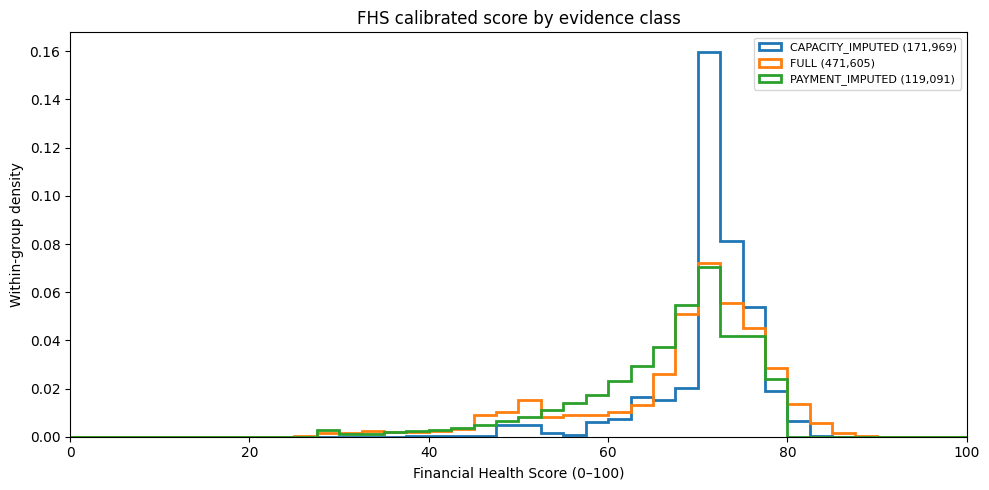

In [18]:
cov=(output.groupby('SCORE_EVIDENCE_FLAG').agg(CUSTOMERS=('SKP_CLIENT','size'),
     SCORED=('FINANCIAL_HEALTH_SCORE','count'),WRITTEN_OFF=('WRITTEN_OFF_OBSERVED','sum'),
     MEAN=('FINANCIAL_HEALTH_SCORE','mean'),MEDIAN=('FINANCIAL_HEALTH_SCORE','median'),
     STD=('FINANCIAL_HEALTH_SCORE','std')).reset_index())
cov['PCT_OF_ALL']=100*cov.CUSTOMERS/N
cov.to_csv(TABLES/'09_coverage_and_distribution.csv',index=False,encoding='utf-8-sig')
display(cov.round(2))
fig,ax=plt.subplots(figsize=(10,5))
for f,g in output.groupby('SCORE_EVIDENCE_FLAG'):
    if g.FINANCIAL_HEALTH_SCORE.notna().any():
        ax.hist(g.FINANCIAL_HEALTH_SCORE.dropna(),bins=np.linspace(0,100,41),histtype='step',
                density=True,lw=2,label=f'{f} ({len(g):,})')
ax.set(xlim=(0,100),xlabel='Financial Health Score (0–100)',ylabel='Within-group density',
       title='FHS calibrated score by evidence class')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIGS/'01_fhs_by_evidence.png',dpi=160)
plt.show()

## 19 · Tạo cấu hình phiên bản & xuất kết quả chấm điểm cuối

In [19]:
selection={'scoring_version':CONFIG['version'],'income_period_confirmed':False,
 'payment_maturity_confirmed':False,'capacity_weight':WEIGHT_C,'a1_weight':WEIGHT_A1,
 'prior_k':k_selected,'prior_k_mle':k_hat,'prior_k_boundary':bool(boundary),
 'p0_due_case_proxy':p0,'odsr_good':CONFIG['odsr_good'],
 'odsr_stress':CONFIG['odsr_stress'],'residual_p10':float(qlo),'residual_p90':float(qhi),
 'written_off_cap':CONFIG['wo_cap'],'imputation_for_missing_capacity':method_c,
 'imputation_for_missing_payment':method_p,'min_group_size':CONFIG['reference_group_min'],
 'source_mart':str(MART),'generated_utc':datetime.now(timezone.utc).isoformat(),
 'selection_principle':'Financial coherence and stability; no PD or approval outcome optimization'}
(OUT/'selected_scoring_config.json').write_text(json.dumps(selection,ensure_ascii=False,indent=2),encoding='utf-8')
FINAL=TABLES/'10_customer_fhs_final.csv'
output.to_csv(FINAL,index=False,float_format='%.6f',encoding='utf-8-sig')
print('FINAL CSV:',FINAL,'| ROWS:',len(output))

FINAL CSV: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_FINAL_VALIDATION_OUTPUT\run_20261018_122943_11af97\tables\10_customer_fhs_final.csv | ROWS: 1000528


## 20 · Approval input: định nghĩa quyết định hợp lệ trước khi đối chiếu

In [20]:
# Contract STATUS semantics: Signed/Active/Finished/Paid off/Written off indicate approved/signed.
# Rejected is an explicit negative decision. Cancelled/Sold/In process etc are NOT rejection.
APPROVED_STATUSES={'SIGNED','ACTIVE','FINISHED','PAID OFF','WRITTEN OFF'}
APPROVED_CONDITIONAL={'APPROVED'}  # Count only with a non-empty APPROVE_CONTRACT_TIME
REJECTED_STATUSES={'REJECTED'}
NEEDED_CONTRACT=['SKP_CREDIT_CASE','SKP_CLIENT','NAME_CREDIT_STATUS',
                 'APPROVE_CONTRACT_TIME','PRODUCT','APPLY_CONTRACT_TIME']
if CONTRACT is None:
    print('Approval alignment SKIPPED: CONTRACT_clean.csv not found. Set CONTRACT_OVERRIDE then rerun.')
else:
    head=pd.read_csv(CONTRACT,nrows=0).columns.tolist()
    miss=set(NEEDED_CONTRACT)-set(head)
    if miss:raise ValueError('CONTRACT_clean thiếu cột: '+str(sorted(miss)))
    print('Approval source:',CONTRACT)
print('Accepted positive:',sorted(APPROVED_STATUSES),'| Explicit rejected:',sorted(REJECTED_STATUSES))

Approval source: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\clean_data\CONTRACT_clean.csv
Accepted positive: ['ACTIVE', 'FINISHED', 'PAID OFF', 'SIGNED', 'WRITTEN OFF'] | Explicit rejected: ['REJECTED']


## 21 · Streaming Contract — kiểm toán STATUS × APPROVE_TIME, không load toàn bộ 4,28M case

In [21]:
status_rows=[];pieces=[];total_contract=0
score_lookup=output.set_index('SKP_CLIENT')['FINANCIAL_HEALTH_SCORE']
flag_lookup=output.set_index('SKP_CLIENT')['SCORE_EVIDENCE_FLAG']
if CONTRACT is not None:
    reader=pd.read_csv(CONTRACT,usecols=NEEDED_CONTRACT,
              dtype={'SKP_CLIENT':'string','SKP_CREDIT_CASE':'string','NAME_CREDIT_STATUS':'string',
                     'PRODUCT':'string','APPROVE_CONTRACT_TIME':'string','APPLY_CONTRACT_TIME':'string'},
              chunksize=CONFIG['approval_chunk_rows'],low_memory=False)
    for batch,ck in enumerate(reader,1):
        total_contract+=len(ck)
        if ck.SKP_CREDIT_CASE.isna().any():raise ValueError('NULL case identifier in clean Contract')
        if ck.SKP_CREDIT_CASE.duplicated().any():raise ValueError('Repeated case within contract chunk')
        status=ck.NAME_CREDIT_STATUS.fillna('').str.strip().str.upper()
        times=ck.APPROVE_CONTRACT_TIME.fillna('').str.strip()
        has_time=(times!='')&(~times.str.upper().isin(['0','XNA','NAN','NAT','NONE','NULL']))
        a=pd.DataFrame({'STATUS':status,'HAS_APPROVE_TIME':has_time})
        count=a.groupby(['STATUS','HAS_APPROVE_TIME'],dropna=False).size().rename('CASES').reset_index()
        status_rows.append(count)
        approval=status.isin(APPROVED_STATUSES)|(status.isin(APPROVED_CONDITIONAL)&has_time)
        rejected=status.isin(REJECTED_STATUSES)
        valid=approval|rejected
        if not valid.any():continue
        small=ck.loc[valid,['SKP_CLIENT','PRODUCT','APPLY_CONTRACT_TIME']].copy()
        small['DECISION_APPROVED']=approval.loc[valid].astype('int8').to_numpy()
        small['FHS']=small.SKP_CLIENT.map(score_lookup)
        small['EVIDENCE']=small.SKP_CLIENT.map(flag_lookup).fillna('NOT_IN_MART')
        small=small[small.FHS.notna()].copy()
        if small.empty:continue
        small['SCORE_BAND']=pd.cut(small.FHS.clip(upper=np.nextafter(100.,0.)),
                       bins=CONFIG['diag_bands'],right=False,include_lowest=True,
                       labels=['0-20','20-40','40-60','60-80','80-100']).astype('string')
        small['PRODUCT']=small.PRODUCT.fillna('UNKNOWN').str.upper().str.strip()
        dt=pd.to_datetime(small.APPLY_CONTRACT_TIME,errors='coerce')
        small['APPLICATION_YEAR']=dt.dt.year.fillna(-1).astype('int16')
        keys=['SCORE_BAND','EVIDENCE','PRODUCT','APPLICATION_YEAR']
        grp=small.groupby(keys,observed=True,dropna=False).agg(
            N_VALID=('DECISION_APPROVED','size'),N_APPROVED=('DECISION_APPROVED','sum')).reset_index()
        pieces.append(grp)
        if batch%5==0:print('Read cases:',f'{total_contract:,}')
    status_audit=pd.concat(status_rows).groupby(['STATUS','HAS_APPROVE_TIME'],as_index=False)['CASES'].sum()
    status_audit.to_csv(TABLES/'11_contract_status_approval_audit.csv',index=False,encoding='utf-8-sig')
    display(status_audit.sort_values('CASES',ascending=False).head(18))
    print('CONTRACT cases read:',f'{total_contract:,}')
else:print('No contract source; skipped.')

Read cases: 1,000,000
Read cases: 2,000,000
Read cases: 3,000,000
Read cases: 4,000,000


,STATUS,HAS_APPROVE_TIME,CASES
4,FINISHED,True,2017785
8,REJECTED,False,914467
0,ACTIVE,True,847515
2,CANCELLED,False,311864
3,CANCELLED,True,165813
11,WRITTEN OFF,True,14520
7,PAID OFF,True,5598
9,SIGNED,True,1772
1,APPROVED,True,483
10,SOLD,True,387


CONTRACT cases read: 4,280,377


## 22 · Approval Rate theo FHS, FULL/IMPUTED, Product, Cohort

In [22]:
def wilson_interval(success,total):
    n=np.asarray(total,float);s=np.asarray(success,float);z=1.96
    p=np.divide(s,n,out=np.full_like(n,np.nan),where=n>0)
    center=(p+z*z/(2*np.maximum(n,1)))/(1+z*z/np.maximum(n,1))
    rad=z*np.sqrt(p*(1-p)/np.maximum(n,1)+z*z/(4*np.maximum(n,1)**2))/(1+z*z/np.maximum(n,1))
    return 100*np.maximum(0,center-rad),100*np.minimum(1,center+rad)

def approval_rollup(data,group_cols):
    ans=data.groupby(group_cols,dropna=False,observed=True)[['N_VALID','N_APPROVED']].sum().reset_index()
    ans['APPROVAL_RATE_PCT']=100*ans.N_APPROVED/ans.N_VALID
    ans['WILSON_LO_PCT'],ans['WILSON_HI_PCT']=wilson_interval(ans.N_APPROVED,ans.N_VALID)
    ans['SUFFICIENT_N']=ans.N_VALID>=CONFIG['minimum_approval_cases_per_band']
    return ans

if pieces:
    approvals=pd.concat(pieces,ignore_index=True)
    approvals=approval_rollup(approvals,['SCORE_BAND','EVIDENCE','PRODUCT','APPLICATION_YEAR'])
    approvals.to_csv(TABLES/'12_approval_product_cohort_evidence.csv',index=False,encoding='utf-8-sig')
    ab=approval_rollup(approvals,['SCORE_BAND']);ab.to_csv(TABLES/'13_approval_by_score_band.csv',index=False)
    ae=approval_rollup(approvals,['SCORE_BAND','EVIDENCE']);ae.to_csv(TABLES/'14_approval_by_evidence.csv',index=False)
    ap=approval_rollup(approvals,['SCORE_BAND','PRODUCT']);ap.to_csv(TABLES/'15_approval_by_product.csv',index=False)
    display(ab.round(2))
else:
    print('No valid decisions with FHS; inspect contract status audit or source.')

,SCORE_BAND,N_VALID,N_APPROVED,APPROVAL_RATE_PCT,WILSON_LO_PCT,WILSON_HI_PCT,SUFFICIENT_N
0,0-20,1765,1466,83.06,81.24,84.74,True
1,20-40,83653,73774,88.19,87.97,88.41,True
2,40-60,491063,378938,77.17,77.05,77.28,True
3,60-80,2559726,2105187,82.24,82.20,82.29,True
4,80-100,278049,233795,84.08,83.95,84.22,True


## 23 · Approval visualization, descriptive only (NOT model optimization)

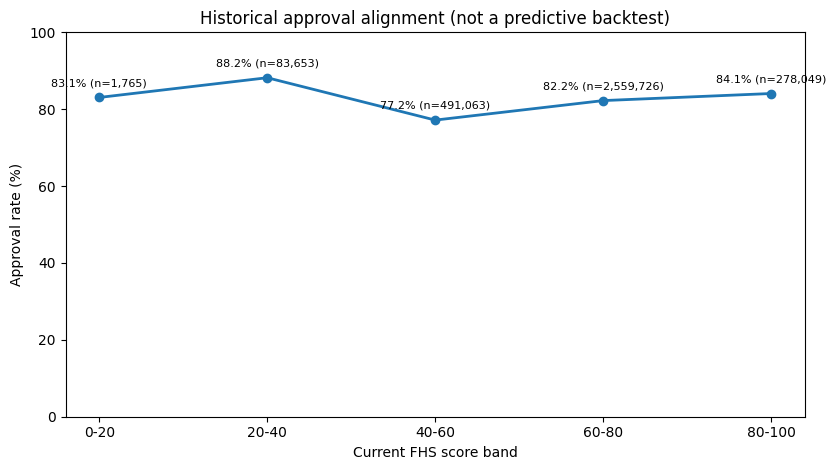

READ CAREFULLY: scores contain events AFTER past approval; no prediction/causal interpretation.
Wilson intervals are approximate CASE-LEVEL intervals; repeat customers violate case independence.


In [23]:
if pieces:
    order=['0-20','20-40','40-60','60-80','80-100']
    z=ab.set_index('SCORE_BAND').reindex(order)
    fig,ax=plt.subplots(figsize=(8.5,4.8))
    x=np.arange(len(order));val=z.APPROVAL_RATE_PCT.to_numpy(float)
    ax.plot(x,val,'o-',lw=2,label='Observed approval rate')
    ax.set(xticks=x,xticklabels=order,xlabel='Current FHS score band',ylabel='Approval rate (%)',
           ylim=(0,100),title='Historical approval alignment (not a predictive backtest)')
    for i,(r,n) in enumerate(zip(val,z.N_VALID)):
        if np.isfinite(r):ax.annotate(f'{r:.1f}% (n={int(n):,})',(i,r),xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
    fig.tight_layout();fig.savefig(FIGS/'02_approval_by_fhs_band.png',dpi=170)
    plt.show()
    print('READ CAREFULLY: scores contain events AFTER past approval; no prediction/causal interpretation.')
    print('Wilson intervals are approximate CASE-LEVEL intervals; repeat customers violate case independence.')

## 24 · Baseline V2 comparison (same customers) and final sign-off checks

In [24]:
if PREVIOUS is not None:
    prev=pd.read_csv(PREVIOUS,usecols=['SKP_CLIENT','FINANCIAL_HEALTH_SCORE','SCORE_EVIDENCE_FLAG'],
                    dtype={'SKP_CLIENT':'string'})
    same=output[['SKP_CLIENT','FINANCIAL_HEALTH_SCORE']].merge(prev[['SKP_CLIENT','FINANCIAL_HEALTH_SCORE']],
        on='SKP_CLIENT',suffixes=('_FINAL','_V2'),validate='one_to_one')
    both=same.FINANCIAL_HEALTH_SCORE_FINAL.notna()&same.FINANCIAL_HEALTH_SCORE_V2.notna()
    err=np.abs(same.loc[both,'FINANCIAL_HEALTH_SCORE_FINAL']-same.loc[both,'FINANCIAL_HEALTH_SCORE_V2'])
    difference=pd.DataFrame([{'BOTH_SCORED':int(both.sum()),'NEW_SCORED':int(same.FINANCIAL_HEALTH_SCORE_FINAL.notna().sum()),
       'PREVIOUS_SCORED':int(same.FINANCIAL_HEALTH_SCORE_V2.notna().sum()),
       'P50_ABS_CHANGE':float(np.median(err)),'P95_ABS_CHANGE':float(np.quantile(err,.95))}])
    difference.to_csv(TABLES/'16_final_vs_v2.csv',index=False);display(difference.round(3))
else:print('V2 old output not available; omitted comparison.')
assert output.SKP_CLIENT.nunique()==N
assert np.isnan(FHS[FLAG=='NO_EVIDENCE']).all()
assert output.FINANCIAL_HEALTH_SCORE.between(0,100)[finite].all()
assert (output.FINANCIAL_HEALTH_SCORE[WO&finite]<=CONFIG['wo_cap']+1e-9).all()
print('ALL FINAL CHECKS PASSED; OUTPUT:',OUT)

,BOTH_SCORED,NEW_SCORED,PREVIOUS_SCORED,P50_ABS_CHANGE,P95_ABS_CHANGE
0,762665,762665,762665,0.766,1.45


ALL FINAL CHECKS PASSED; OUTPUT: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_FINAL_VALIDATION_OUTPUT\run_20261018_122943_11af97


## Phương pháp và giới hạn (dùng trong README / slide)
- **A1:** `ANNUITY` Active/`income_candidate` là *observed debt-service proxy*, **không phải DTI đã được xác nhận**. Các threshold là quy tắc thiết kế cần sensitivity check.
- **A2:** `income_candidate − Active ANNUITY`, scale P10–P90; không phải disposable income sau chi phí sống.
- **P1:** Beta-binomial posterior shrinkage trên DUE/resolved-status case proxy. `k` fitted by marginal likelihood (bounded; reject boundary fit); đây **không phải dự báo default**.
- **P3:** Written-off cap = **business guardrail**, không phải loss prediction. Không áp dụng thêm double penalty.
- **Imputation:** masked FULL holdout (hai tình huống còn/mất Product–Cohort); actual missing-data distribution khác holdout nên ghi cảnh báo selection bias. FULL, IMPUTED, NO_EVIDENCE luôn được lưu.
- **Automatic policy selection:** pass financial monotonicity, finite/range, stability; tie-break by parity baseline. Không có external health label nên **không thể tuyên bố trọng số tối ưu thống kê**.
- **Approval Rate:** tử số là signed/approved outcomes, mẫu số chỉ gồm *approved vs explicitly rejected*, exclude Cancelled, Sold, In Process. Đây là **association hậu nghiệm**, không dùng để fit parameter, không là AUC predictive backtest.
- **NO_EVIDENCE:** Không tạo FHS giả. Đầu ra vẫn chứa khách hàng và cờ nhu cầu bổ sung dữ liệu. 
- **Separate sources:** Approval analysis dùng `PRODUCT` và `APPLY_CONTRACT_TIME` của hồ sơ xét duyệt, không dùng `PRODUCT_CONTEXT` từ hợp đồng nguồn thu nhập.
- **Output:** Final score + evidence + segments, decision transparency (`01`–`16` tables), charts and `selected_scoring_config.json`.